# Project 1, Part B: test the models in your world

Needs the Part A checkpoints and `my_models.py`, and your photos in `p1/photos/` (layout and file names: see P1_0 and the handout).
Models: A2 (concatenated features), A4, A6-H, unchanged until B5. Predictions are always 19-way; each model gets your photos at its own input size (`load_photo(path, 64)` or `224`).

On Colab, start in a fresh session (Runtime > Disconnect and delete runtime in the previous notebook), and finish the Google Drive pop-up that the first cell opens.

Write your own training, evaluation, and visualization code (PyTorch, torchvision, OpenCV, scikit-learn, timm). A1 to A5 use no pretrained weights. AI tools may help you study; they may not write your code or report.

Library functions are listed in each step below, and in full in the handout's Appendix A.

In [16]:
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:                 # every notebook of the project shares one folder on your Google Drive
    from google.colab import drive
    try:                     # a sign-in pop-up opens: finish it within 10 minutes (Colab's default is 2)
        drive.mount('/content/drive', timeout_ms=600_000)
    except Exception as e:
        raise RuntimeError('Google Drive did not mount. Run this cell again and finish the sign-in pop-up, '
                           'with the same Google account in every notebook.') from e
ROOT = os.environ.get('P1_ROOT') or ('/content/drive/MyDrive/p1' if IN_COLAB else os.path.abspath('p1'))
os.environ['P1_ROOT'] = ROOT
os.makedirs(ROOT, exist_ok=True)
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print('project folder:', ROOT)
assert os.path.exists(os.path.join(ROOT, 'p1_utils.py')), 'Run P1_0_Setup_and_Data.ipynb first: it writes p1_utils.py.'
from p1_utils import *
print_versions()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
project folder: /content/drive/MyDrive/p1
versions: python 3.13.16, torch 2.14.1+cu130, torchvision 0.29.1+cu130, timm 1.0.30, numpy 2.4.6, scikit-learn 1.6.1, pandas 2.2.3, matplotlib 3.10.0, pillow 11.3.0, pillow-heif 1.8.1, opencv 4.14.0, gpu Tesla T4


{'python': '3.13.16',
 'torch': '2.14.1+cu130',
 'torchvision': '0.29.1+cu130',
 'timm': '1.0.30',
 'numpy': '2.4.6',
 'scikit-learn': '1.6.1',
 'pandas': '2.2.3',
 'matplotlib': '3.10.0',
 'pillow': '11.3.0',
 'pillow-heif': '1.8.1',
 'opencv': '4.14.0',
 'gpu': 'Tesla T4'}

In [17]:
import torch, torch.nn as nn, torch.nn.functional as F
DEV = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', DEV)
MY_CLASSES = ['bottle', 'bus', 'chair', 'diningtable', 'sofa']     # TODO: your five classes (same in every notebook)

device: cuda


In [18]:
try:                                              # your classes and helpers, written in P1_A
    from my_models import *
except ImportError:
    print('my_models.py not found yet: write it in P1_A_Classifier_Ladder')

In [19]:
print(MY_CLASSES)

['bottle', 'bus', 'chair', 'diningtable', 'sofa']


In [20]:
import os

PHOTO_DIR = '/content/drive/MyDrive/p1/photos'
B1_DIR = os.path.join(PHOTO_DIR, 'B1')
B3_DIR = os.path.join(PHOTO_DIR, 'B3')

print("PHOTO_DIR:", PHOTO_DIR)
print("PHOTO_DIR exists:", os.path.exists(PHOTO_DIR))
print("B1 folders:", os.listdir(B1_DIR))
print("B3 folders:", os.listdir(B3_DIR))

PHOTO_DIR: /content/drive/MyDrive/p1/photos
PHOTO_DIR exists: True
B1 folders: ['bottle', 'bus', 'diningtable', 'chair', 'sofa']
B3 folders: ['bottle', 'bus', 'chair', 'diningtable', 'sofa']


In [21]:
CHOSEN_FACTOR = 'distance'          # TODO: your third B3 factor: 'viewpoint', 'lighting', or 'distance'
check_photos(MY_CLASSES, CHOSEN_FACTOR)   # lists missing photos; rerun after adding photos (add b5_factor= for B5)

photos complete


True

In [22]:
# TODO Load A2 (concatenated features: statistics and classifier), A4 and A6-H from CKPT_DIR.
# Functions: torch.load(path, map_location=DEV); model.load_state_dict(state); np.load(path) (A2 statistics);
#    model.eval()
import timm
stats = np.load(os.path.join(CKPT_DIR, "a2_feature_stats.npz"))

A2_STATS = {
    k: (stats[k + "_mean"], stats[k + "_std"])
    for k in ["hsv", "hog", "gabor"]
}

a2_dim = sum(len(A2_STATS[k][0]) for k in A2_STATS)

model_a2 = nn.Linear(a2_dim, 19).to(DEV)
model_a2.load_state_dict(torch.load(
    os.path.join(CKPT_DIR, "a2_all.pt"),
    map_location=DEV,
    weights_only=True
))
model_a2.eval()

class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = F.relu(out + self.shortcut(x))
        return out


class A4(nn.Module):
    def __init__(self):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 7, stride=1, padding=3, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )

        self.stage1 = nn.Sequential(
            BasicBlock(32, 32),
            BasicBlock(32, 32)
        )

        self.stage2 = nn.Sequential(
            BasicBlock(32, 64, stride=2),
            BasicBlock(64, 64)
        )

        self.stage3 = nn.Sequential(
            BasicBlock(64, 128, stride=2),
            BasicBlock(128, 128)
        )

        self.fc = nn.Linear(128, 19)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = x.mean(dim=(2, 3))
        return self.fc(x)


model_a4 = A4().to(DEV)
model_a4.load_state_dict(torch.load(
    os.path.join(CKPT_DIR, "a4.pt"),
    map_location=DEV,
    weights_only=True
))
model_a4.eval()

model_a6h = timm.create_model(
    "vit_tiny_patch16_224.augreg_in21k_ft_in1k",
    pretrained=False,
    num_classes=19
).to(DEV)

model_a6h.load_state_dict(torch.load(
    os.path.join(CKPT_DIR, "a6_h.pt"),
    map_location=DEV,
    weights_only=True
))
model_a6h.eval()

A6_MEAN = model_a6h.pretrained_cfg["mean"]
A6_STD = model_a6h.pretrained_cfg["std"]

print("A2 loaded")
print("A4 loaded")
print("A6-H loaded")
print("All models ready")

A2 loaded
A4 loaded
A6-H loaded
All models ready


In [23]:
# TODO Reload check, before using any reloaded model: recompute its VOC test mean per-class accuracy (19 classes)
# and confirm it matches Table 1 from P1_A. If it does not, this notebook's preprocessing differs from P1_A's
# (for example, A6 needs its checkpoint's mean and std, not the usual ImageNet values): fix that first.

import pandas as pd
X64, y, img_id, is_test = load_crops(64)
idx_train, idx_val, idx_test = make_splits(img_id, is_test)

def mean_class_acc(pred, target, classes):
    return np.mean([
        (pred[target == c] == target[target == c]).float().mean().item()
        for c in classes
    ])

results = {}
voc_accuracies_5 = {}

features = {}

for k in ["hsv", "hog", "gabor"]:
    f = np.stack([FEAT_FNS[k](im) for im in X64[idx_test]])
    m, s = A2_STATS[k]
    features[k] = (f - m) / s

x = concat_features(features)

with torch.no_grad():
    x = torch.tensor(x, dtype=torch.float32, device=DEV)
    pred = model_a2(x).argmax(1).cpu()

labels = torch.tensor(y[idx_test])
results["A2-all"] = mean_class_acc(pred, labels, range(19))
voc_accuracies_5["A2-all"] = mean_class_acc(
    pred, labels, [CLASSES.index(c) for c in MY_CLASSES]
)

predictions = []

model_a4.eval()

with torch.no_grad():
    for i in range(0, len(idx_test), 32):
        b = idx_test[i:i+32]
        x = torch.tensor(X64[b], dtype=torch.float32, device=DEV)
        x = x.permute(0, 3, 1, 2) / 255.0
        predictions.append(model_a4(x).argmax(1).cpu())

pred = torch.cat(predictions)
results["A4"] = mean_class_acc(pred, labels, range(19))
voc_accuracies_5["A4"] = mean_class_acc(
    pred, labels, [CLASSES.index(c) for c in MY_CLASSES]
)

del X64

X224, _, _, _ = load_crops(224)

mean = torch.tensor(A6_MEAN, device=DEV).view(1, 3, 1, 1)
std = torch.tensor(A6_STD, device=DEV).view(1, 3, 1, 1)

predictions = []

model_a6h.eval()

with torch.no_grad():
    for i in range(0, len(idx_test), 32):
        b = idx_test[i:i+32]
        x = torch.tensor(X224[b], dtype=torch.float32, device=DEV)
        x = x.permute(0, 3, 1, 2) / 255.0
        x = (x - mean) / std
        predictions.append(model_a6h(x).argmax(1).cpu())

pred = torch.cat(predictions)
results["A6-H"] = mean_class_acc(pred, labels, range(19))
voc_accuracies_5["A6-H"] = mean_class_acc(
    pred, labels, [CLASSES.index(c) for c in MY_CLASSES]
)

del X224

table = pd.read_csv(os.path.join(RESULTS_DIR, "table1.csv"))

for name, acc in results.items():
    row = table[table["model"] == name]

    if len(row) == 0:
        print(name, "Test accuracy:", round(acc, 4), "Not found in Table 1")
    else:
        old_acc = float(row.iloc[0]["mean_acc_19"])
        match = np.isclose(acc, old_acc, atol=1e-5)

        print(name)
        print("Part A:", round(old_acc, 4))
        print("Part B:", round(acc, 4))
        print("Match:", match)
        print()

A2-all
Part A: 0.4375
Part B: 0.4375
Match: True

A4 Test accuracy: 0.5126 Not found in Table 1
A6-H Test accuracy: 0.921 Not found in Table 1


## B1: ordinary photos

In [24]:
B1_DIR = os.path.join(PHOTO_DIR, 'B1')
X1_64, y1, paths1 = load_photo_folder(B1_DIR, 64)
X1_224, _, _ = load_photo_folder(B1_DIR, 224)
print(len(y1), 'B1 photos')

50 B1 photos


In [25]:
# TODO B1: mean per-class accuracy of A2, A4, A6-H on your photos vs. VOC test accuracy on the same five classes. How do your photos differ from VOC?
# Functions: torch.no_grad(); logits.argmax(1)

import pandas as pd

features = {}

for k in ["hsv", "hog", "gabor"]:
    f = np.stack([FEAT_FNS[k](im) for im in X1_64])
    m, s = A2_STATS[k]
    features[k] = (f - m) / s

x_a2 = concat_features(features)

with torch.no_grad():
    x = torch.tensor(x_a2, dtype=torch.float32, device=DEV)
    pred_a2 = model_a2(x).argmax(1).cpu().numpy()


pred_a4 = []

model_a4.eval()

with torch.no_grad():
    for i in range(0, len(X1_64), 32):
        x = torch.tensor(X1_64[i:i+32], dtype=torch.float32, device=DEV)
        x = x.permute(0, 3, 1, 2) / 255.0
        pred_a4.extend(model_a4(x).argmax(1).cpu().numpy())

pred_a4 = np.array(pred_a4)


mean = torch.tensor(A6_MEAN, device=DEV).view(1, 3, 1, 1)
std = torch.tensor(A6_STD, device=DEV).view(1, 3, 1, 1)

pred_a6 = []

model_a6h.eval()

with torch.no_grad():
    for i in range(0, len(X1_224), 32):
        x = torch.tensor(X1_224[i:i+32], dtype=torch.float32, device=DEV)
        x = x.permute(0, 3, 1, 2) / 255.0
        x = (x - mean) / std
        pred_a6.extend(model_a6h(x).argmax(1).cpu().numpy())

pred_a6 = np.array(pred_a6)

table = pd.read_csv(os.path.join(RESULTS_DIR, "table1.csv"))

rows = []

for name, pred in [
    ("A2-all", pred_a2),
    ("A4", pred_a4),
    ("A6-H", pred_a6)
]:
    acc = np.mean([
        np.mean(pred[y1 == c] == c)
        for c in np.unique(y1)
    ])


    voc_acc = voc_accuracies_5[name]


    rows.append({
        "model": name,
        "VOC_accuracy_5": voc_acc,
        "B1_accuracy_5": acc,
        "difference": acc - voc_acc
    })

b1_results = pd.DataFrame(rows)

display(b1_results)

b1_results.to_csv(
    os.path.join(RESULTS_DIR, "b1_results.csv"),
    index=False
)


,model,VOC_accuracy_5,B1_accuracy_5,difference
0,A2-all,0.418119,0.20,-0.218119
1,A4,0.404367,0.26,-0.144367
2,A6-H,0.862561,0.88,0.017439


**B2** is a written prediction in the milestone (which factor hurts A6-H most, which model is most robust to each), made before you shoot or evaluate B3. No code.

## B3: controlled series

Set your chosen factor, load the series, run the three models, plot one panel per factor, and export `b3_results.csv`.

In [26]:
B3_DIR = os.path.join(PHOTO_DIR, 'B3')                     # CHOSEN_FACTOR is set at the top
recs64 = load_b3_series(B3_DIR, 64, CHOSEN_FACTOR)
recs224 = load_b3_series(B3_DIR, 224, CHOSEN_FACTOR)
print(len(recs64), 'B3 images')
# rows = b3_rows(recs64, 'A2', probs_a2) + b3_rows(recs64, 'A4', probs_a4) + b3_rows(recs224, 'A6-H', probs_a6h)
# write_b3_csv(rows, os.path.join(RESULTS_DIR, 'b3_results.csv'))

print(len(recs224), 'B3 images')

90 B3 images
90 B3 images


wrote 270 rows to /content/drive/MyDrive/p1/results/b3_results.csv, and kept 40 rows of other models
['object', 'class', 'factor', 'condition', 'model', 'pred', 'correct', 'correctness']


,object,class,factor,condition,model,pred,correct,correctness
0,bottle/object1,bottle,rotation,0,A2,bus,0,0
1,bottle/object1,bottle,rotation,30,A2,cat,0,0
2,bottle/object1,bottle,rotation,90,A2,chair,0,0
3,bottle/object1,bottle,rotation,180,A2,boat,0,0
4,bottle/object1,bottle,occlusion,none,A2,bus,0,0
...,...,...,...,...,...,...,...,...
265,sofa/object2,sofa,occlusion,none,A6-H,sofa,1,1
266,sofa/object2,sofa,occlusion,quarter,A6-H,chair,0,0
267,sofa/object2,sofa,occlusion,half,A6-H,chair,0,0
268,sofa/object2,sofa,distance,near,A6-H,sofa,1,1


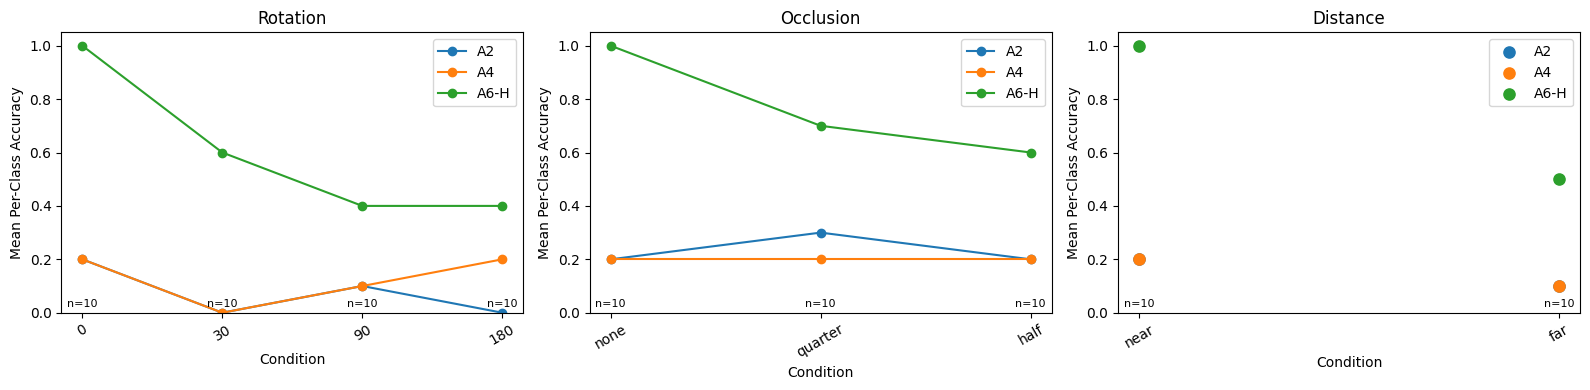

model                                      A2  A4  A6-H
object         class  factor    condition              
bottle/object1 bottle distance  far         0   0     0
                                near        0   0     1
                      occlusion half        0   0     0
                                none        0   0     1
                                quarter     0   0     0
...                                        ..  ..   ...
sofa/object2   sofa   occlusion quarter     0   0     0
                      rotation  0           0   0     1
                                180         0   0     0
                                30          0   0     1
                                90          0   0     0

[90 rows x 3 columns]

B3 results saved


In [27]:
# TODO B3: one panel per factor, each model's mean per-class accuracy over your five classes at each condition, with sample
# counts: lines for rotation and occlusion, separate markers for viewpoint or lighting categories. Values move in steps of 0.1
# (two objects per class). Show each object's outcomes in a table.
# Functions: b3_rows(recs, model_name, probs); write_b3_csv(rows, path); plt.subplots(1, 3); pd.DataFrame(rows)


import pandas as pd
import matplotlib.pyplot as plt

images64 = np.stack([r["image"] for r in recs64])
images224 = np.stack([r["image"] for r in recs224])

features = {}

for k in ["hsv", "hog", "gabor"]:
    f = np.stack([FEAT_FNS[k](im) for im in images64])
    m, s = A2_STATS[k]
    features[k] = (f - m) / s

x_a2 = concat_features(features)

with torch.no_grad():
    x = torch.tensor(x_a2, dtype=torch.float32, device=DEV)
    probs_a2 = model_a2(x).softmax(1).cpu().numpy()

probs_a4 = []

with torch.no_grad():
    for i in range(0, len(images64), 32):
        x = torch.tensor(images64[i:i+32], dtype=torch.float32, device=DEV)
        x = x.permute(0, 3, 1, 2) / 255.0
        probs_a4.append(model_a4(x).softmax(1).cpu().numpy())

probs_a4 = np.concatenate(probs_a4)

mean = torch.tensor(A6_MEAN, device=DEV).view(1, 3, 1, 1)
std = torch.tensor(A6_STD, device=DEV).view(1, 3, 1, 1)

probs_a6h = []

with torch.no_grad():
    for i in range(0, len(images224), 32):
        x = torch.tensor(images224[i:i+32], dtype=torch.float32, device=DEV)
        x = x.permute(0, 3, 1, 2) / 255.0
        x = (x - mean) / std
        probs_a6h.append(model_a6h(x).softmax(1).cpu().numpy())

probs_a6h = np.concatenate(probs_a6h)

rows = (
    b3_rows(recs64, "A2", probs_a2)
    + b3_rows(recs64, "A4", probs_a4)
    + b3_rows(recs224, "A6-H", probs_a6h)
)

write_b3_csv(rows, os.path.join(RESULTS_DIR, "b3_results.csv"))

df = pd.DataFrame(rows)

if "correctness" not in df.columns:
    if "correct" in df.columns:
        df["correctness"] = df["correct"]
    else:
        df["correctness"] = (
            df["prediction"] == df["class"]
        ).astype(int)

print(df.columns.tolist())


display(df)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, factor in zip(axes, ["rotation", "occlusion", CHOSEN_FACTOR]):
    data = df[df["factor"] == factor]

    conditions = list(dict.fromkeys(data["condition"]))

    for model in ["A2", "A4", "A6-H"]:
        subset = data[data["model"] == model]

        accuracies = []
        counts = []

        for condition in conditions:
            group = subset[subset["condition"] == condition]
            accuracies.append(group["correctness"].mean())
            counts.append(len(group))

        if factor == "distance":
            ax.scatter(conditions, accuracies, label=model, s=65)
        else:
            ax.plot(conditions, accuracies, marker="o", label=model)

    ax.set_title(factor.capitalize())
    ax.set_xlabel("Condition")
    ax.set_ylabel("Mean Per-Class Accuracy")
    ax.set_ylim(0, 1.05)
    ax.legend()
    ax.tick_params(axis="x", rotation=30)

    for j, condition in enumerate(conditions):
        n = len(data[(data["condition"] == condition) & (data["model"] == "A2")])
        ax.text(j, 0.02, f"n={n}", ha="center", fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "b3_accuracy.png"))
plt.show()

object_table = df.pivot_table(
    index=["object", "class", "factor", "condition"],
    columns="model",
    values="correctness",
    aggfunc="first"
)

display(object_table)

object_table.to_csv(os.path.join(RESULTS_DIR, "b3_object_results.csv"))

print("B3 results saved")


## B4: three minimal pairs

Pair 1: near
True class: bottle
bottle 1.0
diningtable 0.0
tvmonitor 0.0
A2 correct: False
A4 correct: False
A6-H correct: True

Pair 1: far
True class: bottle
diningtable 0.9783
sofa 0.011
chair 0.0065
A2 correct: False
A4 correct: False
A6-H correct: False



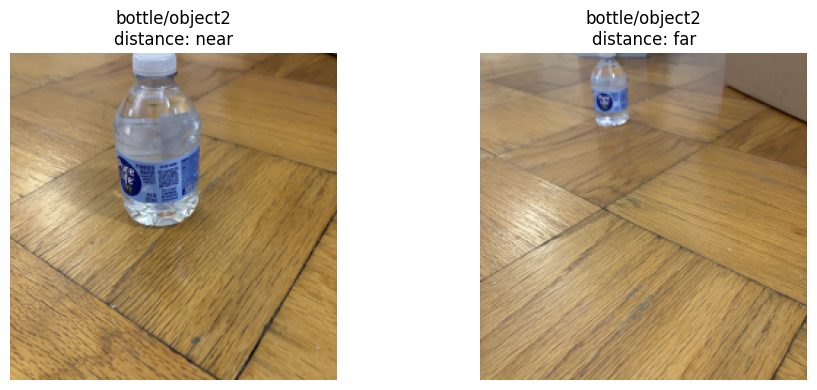

Pair 2: none
True class: sofa
sofa 0.9974
chair 0.0026
pottedplant 0.0
A2 correct: False
A4 correct: False
A6-H correct: True

Pair 2: half
True class: sofa
chair 0.9944
sofa 0.0034
pottedplant 0.0018
A2 correct: False
A4 correct: False
A6-H correct: False



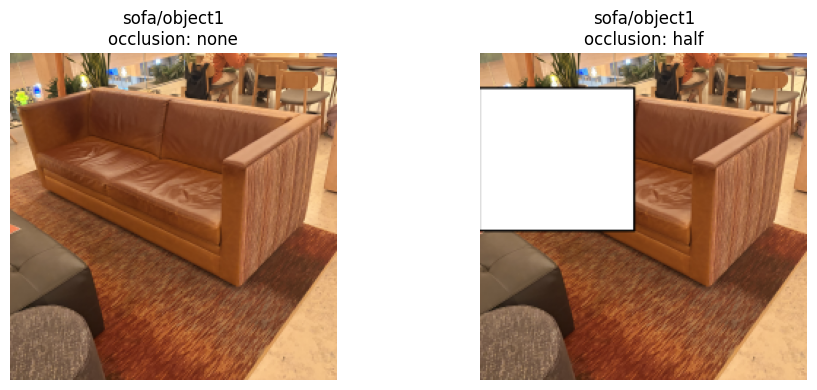

Pair 3: 0
True class: bus
bus 0.9986
train 0.0013
car 0.0
A2 correct: False
A4 correct: False
A6-H correct: True

Pair 3: 90
True class: bus
train 0.5848
motorbike 0.3315
bottle 0.0309
A2 correct: False
A4 correct: False
A6-H correct: False



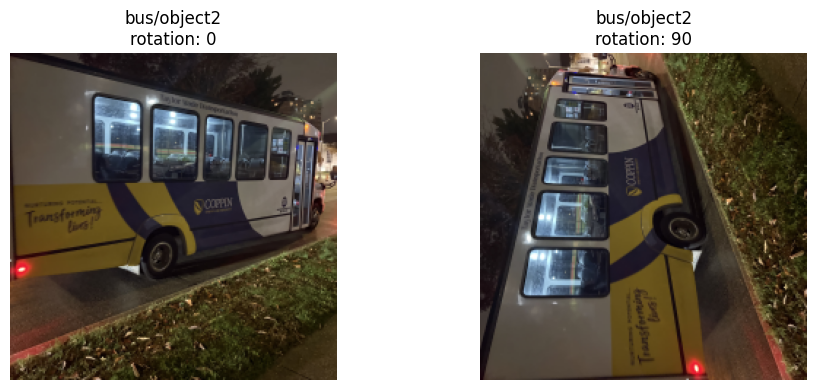

,pair,object,class,factor,condition,A2_correct,A4_correct,A6H_correct,A6H_true_probability,top3,right_wrong_pair
0,1,bottle/object2,bottle,distance,near,False,False,True,0.999958,"bottle: 1.000, diningtable: 0.000, tvmonitor: ...",True
1,1,bottle/object2,bottle,distance,far,False,False,False,0.001822,"diningtable: 0.978, sofa: 0.011, chair: 0.006",True
2,2,sofa/object1,sofa,occlusion,none,False,False,True,0.997366,"sofa: 0.997, chair: 0.003, pottedplant: 0.000",True
3,2,sofa/object1,sofa,occlusion,half,False,False,False,0.003418,"chair: 0.994, sofa: 0.003, pottedplant: 0.002",True
4,3,bus/object2,bus,rotation,0,False,False,True,0.998644,"bus: 0.999, train: 0.001, car: 0.000",True
5,3,bus/object2,bus,rotation,90,False,False,False,0.007483,"train: 0.585, motorbike: 0.332, bottle: 0.031",True


B4 results saved


In [28]:
# TODO B4: three pairs, each two photos of one object with one deliberate change, three different objects; A6-H right on one
# photo and wrong on the other: both images,
# A6-H top-3 classes and softmax scores, whether A2/A4 fail. At most one pair may be a rotation made in code. If you find fewer
# than three, complete them with the largest drops in A6-H's true-class probability, and say so.
# Functions: F.softmax(logits, dim=1); torch.topk(p, 3)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pairs = []
candidates = []

for i, r in enumerate(recs224):
    if r["condition"] not in ["0", "none", "front", "normal", "near"]:
        continue

    for j, s in enumerate(recs224):
        if r["object"] != s["object"]:
            continue
        if r["factor"] != s["factor"]:
            continue
        if i == j:
            continue

        cls = r["cls"]
        p1 = probs_a6h[i, cls]
        p2 = probs_a6h[j, cls]

        correct1 = probs_a6h[i].argmax() == cls
        correct2 = probs_a6h[j].argmax() == cls

        if correct1 and not correct2:
            candidates.append((True, p1 - p2, i, j))
        else:
            candidates.append((False, p1 - p2, i, j))

candidates.sort(key=lambda x: (x[0], x[1]), reverse=True)

used_objects = set()
rotation_count = 0

for success, drop, i, j in candidates:
    obj = recs224[i]["object"]
    factor = recs224[j]["factor"]

    if obj in used_objects:
        continue

    if factor == "rotation" and rotation_count >= 1:
        continue

    pairs.append((success, drop, i, j))
    used_objects.add(obj)

    if factor == "rotation":
        rotation_count += 1

    if len(pairs) == 3:
        break

if len(pairs) < 3:
    print("Warning: fewer than three valid pairs were found.")

results = []

for number, (success, drop, i, j) in enumerate(pairs, 1):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    for ax, idx in zip(axes, [i, j]):
        r = recs224[idx]
        cls = r["cls"]

        ax.imshow(r["image"])
        ax.axis("off")
        ax.set_title(f'{r["object"]}\n{r["factor"]}: {r["condition"]}')

        top = np.argsort(probs_a6h[idx])[-3:][::-1]

        print(f"Pair {number}: {r['condition']}")
        print("True class:", CLASSES[cls])

        for k in top:
            print(CLASSES[k], round(float(probs_a6h[idx, k]), 4))

        a2_correct = probs_a2[idx].argmax() == cls
        a4_correct = probs_a4[idx].argmax() == cls
        a6_correct = probs_a6h[idx].argmax() == cls

        print("A2 correct:", bool(a2_correct))
        print("A4 correct:", bool(a4_correct))
        print("A6-H correct:", bool(a6_correct))
        print()

        results.append({
            "pair": number,
            "object": r["object"],
            "class": CLASSES[cls],
            "factor": r["factor"],
            "condition": r["condition"],
            "A2_correct": bool(a2_correct),
            "A4_correct": bool(a4_correct),
            "A6H_correct": bool(a6_correct),
            "A6H_true_probability": float(probs_a6h[idx, cls]),
            "top3": ", ".join(
                f"{CLASSES[k]}: {probs_a6h[idx, k]:.3f}"
                for k in top
            ),
            "right_wrong_pair": success
        })

    plt.tight_layout()
    plt.show()

b4_results = pd.DataFrame(results)

display(b4_results)

b4_results.to_csv(
    os.path.join(RESULTS_DIR, "b4_results.csv"),
    index=False
)

print("B4 results saved")


## B5: one repair

In [29]:
# B5 needs the VOC crops again: training crops for the mixed batches, test crops for the final comparison.
# X224, y, img_id, is_test = load_crops(224)                 # 2.5 GB; keep uint8 and convert one batch at a time
# idx_train, idx_val, idx_test = make_splits(img_id, is_test)  # the same split as Part A: adapt with idx_train only

X224, y, img_id, is_test = load_crops(224)

idx_train, idx_val, idx_test = make_splits(img_id, is_test)

print("VOC crops:", X224.shape)
print("Training:", len(idx_train))
print("Validation:", len(idx_val))
print("Test:", len(idx_test))
print("Data type:", X224.dtype)

VOC crops: (16719, 224, 224, 3)
Training: 7541
Validation: 797
Test: 8381
Data type: uint8


In [31]:
# TODO B5: the factor with the largest A6-H drop and its worst non-baseline condition (ties: rotation, occlusion, your factor;
# repair it even if nothing drops). Photograph
# 10 adaptation photos, 2 per class, of objects not in B3, B4, or the held-out test (photos/B5/adapt/), and the held-out photos
# (photos/B5/heldout/), BEFORE the repair; keep the held-out predictions hidden until the run is fixed.
# X_ad, y_ad, _ = load_b5_adapt(os.path.join(PHOTO_DIR, 'B5', 'adapt'), 224, FACTOR, CONDITION)
# held = load_b5_heldout(os.path.join(PHOTO_DIR, 'B5', 'heldout'), 224, FACTOR, CONDITION)
# One fine-tuning run from A6-H with settings and stopping rule fixed in advance (default: 100 updates, keep the final model):
# each update, 8 random VOC training crops and 8 adaptation photos drawn with replacement; one learning rate for all parameters.
# Table rows, original vs. repaired: B3 at the repaired condition; all B3 images, each once (b3_unique(recs224)); held-out
# ordinary; held-out challenging; B1; VOC test (19 classes). Export b5_results.csv with b5_rows and write_b5_csv.
# Functions: check_photos(MY_CLASSES, CHOSEN_FACTOR, b5_factor=FACTOR); copy.deepcopy(model); rng.choice;
#    torch.cat; b3_unique(recs); b5_rows(...); write_b5_csv(rows, path)

import os
import sys
import copy
import importlib.util
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import timm

BASE_DIR = "/content/drive/MyDrive/p1"
PHOTO_DIR = os.path.join(BASE_DIR, "photos")
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")
RESULTS_DIR = os.path.join(BASE_DIR, "results")

sys.path.insert(0, BASE_DIR)

if "p1_utils" not in globals():
    spec = importlib.util.spec_from_file_location(
        "p1_utils",
        os.path.join(BASE_DIR, "p1_utils.py")
    )
    p1_utils = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(p1_utils)

u = p1_utils

FACTOR = "rotation"
CONDITION = "90"
CHOSEN_FACTOR = "distance"

MY_CLASSES = ["bottle", "bus", "chair", "diningtable", "sofa"]

DEV = "cuda" if torch.cuda.is_available() else "cpu"

os.makedirs(RESULTS_DIR, exist_ok=True)

if "model_a6h" not in globals():
    model_a6h = timm.create_model(
        "vit_tiny_patch16_224.augreg_in21k_ft_in1k",
        pretrained=False,
        num_classes=19
    ).to(DEV)

    model_a6h.load_state_dict(
        torch.load(
            os.path.join(CKPT_DIR, "a6_h.pt"),
            map_location=DEV,
            weights_only=True
        )
    )

model_a6h = model_a6h.to(DEV)
model_a6h.eval()

A6_MEAN = model_a6h.pretrained_cfg["mean"]
A6_STD = model_a6h.pretrained_cfg["std"]

checkpoint = os.path.join(CKPT_DIR, "a6_h_repaired.pt")

if not os.path.isfile(checkpoint):
    raise FileNotFoundError(checkpoint)

model_repaired = copy.deepcopy(model_a6h).to(DEV)

model_repaired.load_state_dict(
    torch.load(
        checkpoint,
        map_location=DEV,
        weights_only=True
    )
)

model_repaired.eval()

print("Modelo original cargado")
print("Modelo reparado recuperado")
print("Dispositivo:", DEV)

if "X224" not in globals() or "idx_test" not in globals():
    X224, y, img_id, is_test = u.load_crops(224)
    idx_train, idx_val, idx_test = u.make_splits(
        img_id, is_test
    )

if "recs224" not in globals():
    recs224 = u.load_b3_series(
        os.path.join(PHOTO_DIR, "B3"),
        224,
        CHOSEN_FACTOR
    )

if "X1_224" not in globals() or "y1" not in globals():
    X1_224, y1, paths1 = u.load_photo_folder(
        os.path.join(PHOTO_DIR, "B1"),
        224
    )

held = u.load_b5_heldout(
    os.path.join(PHOTO_DIR, "B5", "heldout"),
    224,
    FACTOR,
    CONDITION
)

mean = torch.tensor(
    A6_MEAN,
    dtype=torch.float32,
    device=DEV
).view(1, 3, 1, 1)

std = torch.tensor(
    A6_STD,
    dtype=torch.float32,
    device=DEV
).view(1, 3, 1, 1)

def prepare_b5(images):
    x = torch.as_tensor(
        np.asarray(images),
        dtype=torch.float32,
        device=DEV
    )
    x = x.permute(0, 3, 1, 2) / 255.0
    return (x - mean) / std

def predict_b5(model, images, batch_size=16):
    model.eval()
    outputs = []

    with torch.no_grad():
        for start in range(0, len(images), batch_size):
            batch = images[start:start + batch_size]
            x = prepare_b5(batch)
            probs = F.softmax(model(x), dim=1)
            outputs.append(probs.cpu().numpy())

    return np.concatenate(outputs, axis=0)

all_rows = []
summary = []

def evaluate_b5(name, records, images):
    if len(records) == 0:
        raise ValueError(f"No hay imágenes para {name}")

    labels = np.asarray(
        [int(r["cls"]) for r in records]
    )

    for model_name, model in [
        ("A6-H", model_a6h),
        ("A6-H-repaired", model_repaired)
    ]:
        probs = predict_b5(model, images)

        rows = u.b5_rows(
            records,
            model_name,
            probs
        )

        for row in rows:
            row["evaluation"] = name

        all_rows.extend(rows)

        pred = probs.argmax(axis=1)

        accuracy = float(np.mean([
            np.mean(pred[labels == c] == c)
            for c in np.unique(labels)
        ]))

        summary.append({
            "evaluation": name,
            "model": model_name,
            "accuracy": accuracy,
            "n": len(labels)
        })

        print(
            name,
            model_name,
            "accuracy:",
            round(accuracy, 4)
        )

b3_condition = [
    r for r in recs224
    if str(r.get("factor", "")) == FACTOR
    and str(r["condition"]) in (
        CONDITION,
        f"{FACTOR}_{CONDITION}"
    )
]

if len(b3_condition) == 0:
    b3_condition = [
        r for r in recs224
        if str(r["condition"]) == f"{FACTOR}_{CONDITION}"
    ]

evaluate_b5(
    "B3 rotation 90",
    b3_condition,
    np.stack([r["image"] for r in b3_condition])
)

unique_b3 = u.b3_unique(recs224)

evaluate_b5(
    "B3 all unique",
    unique_b3,
    np.stack([r["image"] for r in unique_b3])
)

ordinary = [
    r for r in held
    if r["condition"] == "ordinary"
]

challenging = [
    r for r in held
    if r["condition"] == f"{FACTOR}_{CONDITION}"
]

evaluate_b5(
    "Heldout ordinary",
    ordinary,
    np.stack([r["image"] for r in ordinary])
)

evaluate_b5(
    "Heldout challenging",
    challenging,
    np.stack([r["image"] for r in challenging])
)

if "paths1" not in globals():
    _, _, paths1 = u.load_photo_folder(
        os.path.join(PHOTO_DIR, "B1"),
        224
    )

b1_records = [
    {
        "cls": int(y1[i]),
        "object": str(paths1[i]),
        "condition": "ordinary"
    }
    for i in range(len(y1))
]

evaluate_b5(
    "B1",
    b1_records,
    X1_224
)

voc_original = []
voc_repaired = []

model_a6h.eval()
model_repaired.eval()

with torch.no_grad():
    for start in range(0, len(idx_test), 16):
        ids = idx_test[start:start + 16]
        x = prepare_b5(X224[ids])

        p_original = F.softmax(
            model_a6h(x),
            dim=1
        )

        p_repaired = F.softmax(
            model_repaired(x),
            dim=1
        )

        voc_original.append(
            p_original.cpu().numpy()
        )

        voc_repaired.append(
            p_repaired.cpu().numpy()
        )

voc_original = np.concatenate(
    voc_original,
    axis=0
)

voc_repaired = np.concatenate(
    voc_repaired,
    axis=0
)

voc_labels = np.asarray(y)[idx_test]

voc_records = [
    {
        "cls": int(voc_labels[i]),
        "object": f"VOC/test_{i}",
        "condition": "test"
    }
    for i in range(len(idx_test))
]

for model_name, probs in [
    ("A6-H", voc_original),
    ("A6-H-repaired", voc_repaired)
]:
    rows = u.b5_rows(
        voc_records,
        model_name,
        probs
    )

    for row in rows:
        row["evaluation"] = "VOC test 19 classes"

    all_rows.extend(rows)

    pred = probs.argmax(axis=1)

    accuracy = float(np.mean([
        np.mean(pred[voc_labels == c] == c)
        for c in np.unique(voc_labels)
    ]))

    summary.append({
        "evaluation": "VOC test 19 classes",
        "model": model_name,
        "accuracy": accuracy,
        "n": len(voc_labels)
    })

    print(
        "VOC test 19 classes",
        model_name,
        "accuracy:",
        round(accuracy, 4)
    )

results_path = os.path.join(
    RESULTS_DIR,
    "b5_results.csv"
)

summary_path = os.path.join(
    RESULTS_DIR,
    "b5_summary.csv"
)


summary_df = pd.DataFrame(summary)

summary_df.to_csv(
    summary_path,
    index=False
)

display(summary_df)

print("Resultados:", results_path)
print("Resumen:", summary_path)
print("Modelo:", checkpoint)



Modelo original cargado
Modelo reparado recuperado
Dispositivo: cuda
B3 rotation 90 A6-H accuracy: 0.4
B3 rotation 90 A6-H-repaired accuracy: 0.9
B3 all unique A6-H accuracy: 0.6
B3 all unique A6-H-repaired accuracy: 0.8
Heldout ordinary A6-H accuracy: 0.8
Heldout ordinary A6-H-repaired accuracy: 0.8
Heldout challenging A6-H accuracy: 0.2
Heldout challenging A6-H-repaired accuracy: 0.6
B1 A6-H accuracy: 0.88
B1 A6-H-repaired accuracy: 0.92
VOC test 19 classes A6-H accuracy: 0.921
VOC test 19 classes A6-H-repaired accuracy: 0.92


,evaluation,model,accuracy,n
0,B3 rotation 90,A6-H,0.400000,10
1,B3 rotation 90,A6-H-repaired,0.900000,10
2,B3 all unique,A6-H,0.600000,70
3,B3 all unique,A6-H-repaired,0.800000,70
4,Heldout ordinary,A6-H,0.800000,5
5,Heldout ordinary,A6-H-repaired,0.800000,5
6,Heldout challenging,A6-H,0.200000,5
7,Heldout challenging,A6-H-repaired,0.600000,5
8,B1,A6-H,0.880000,50
9,B1,A6-H-repaired,0.920000,50


Resultados: /content/drive/MyDrive/p1/results/b5_results.csv
Resumen: /content/drive/MyDrive/p1/results/b5_summary.csv
Modelo: /content/drive/MyDrive/p1/checkpoints/a6_h_repaired.pt


In [32]:
import os
import pandas as pd

RESULTS_DIR = "/content/drive/MyDrive/p1/results"

os.makedirs(RESULTS_DIR, exist_ok=True)

results_path = os.path.join(RESULTS_DIR, "b5_results.csv")
summary_path = os.path.join(RESULTS_DIR, "b5_summary.csv")

clean_rows = [
    {column: row[column] for column in u.CSV_B5_COLUMNS}
    for row in all_rows
]

u.write_b5_csv(clean_rows, results_path)

summary_df = pd.DataFrame(summary)
summary_df.to_csv(summary_path, index=False)

display(summary_df)

print("B5 completado correctamente")
print("Resultados:", results_path)
print("Resumen:", summary_path)
print("Modelo:", "/content/drive/MyDrive/p1/checkpoints/a6_h_repaired.pt")

wrote 17042 rows to /content/drive/MyDrive/p1/results/b5_results.csv


,evaluation,model,accuracy,n
0,B3 rotation 90,A6-H,0.400000,10
1,B3 rotation 90,A6-H-repaired,0.900000,10
2,B3 all unique,A6-H,0.600000,70
3,B3 all unique,A6-H-repaired,0.800000,70
4,Heldout ordinary,A6-H,0.800000,5
5,Heldout ordinary,A6-H-repaired,0.800000,5
6,Heldout challenging,A6-H,0.200000,5
7,Heldout challenging,A6-H-repaired,0.600000,5
8,B1,A6-H,0.880000,50
9,B1,A6-H-repaired,0.920000,50


B5 completado correctamente
Resultados: /content/drive/MyDrive/p1/results/b5_results.csv
Resumen: /content/drive/MyDrive/p1/results/b5_summary.csv
Modelo: /content/drive/MyDrive/p1/checkpoints/a6_h_repaired.pt


Before you submit: `shrink_photos()` copies your photos, upright and at 1024 px, to `p1/photos_small/` for the zip.